# Algoritmo k-NN (Clasificador)

## Acciones iniciales

Importamos librerías necesarias

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.neighbors import KNeighborsClassifier

Descargamos el dataset "IRIS" desde la web del UC Irvine ML Repository   
![logoUCI](./img/UCILOGO.JPG)


In [2]:
path = "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data"

Asignamos los nombres de columna al dataset

In [3]:
headernames = ['sepal length', 'sepal width', 'petal length', 'petal width', 'class']

Cargamos el dataset en un dataframe

In [4]:
dataset = pd.read_csv(path, names=headernames)
dataset.head()

,sepal length,sepal width,petal length,petal width,class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


### Separación de características y clase

In [5]:
X = dataset.iloc[:, :-1].values
y = dataset.iloc[:, 4].values

### Partición conjunto TRAIN y conjunto TEST

In [6]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4)

#### Proceso de estandarización

La estandarización consiste en transformar la distribución de los valores de los atributos para que estos adopten una media y una desviación típica determinadas. Esta transformación se realiza para cada atributo de manera independiente y se calcula restando a cada valor del atributo la media aritmética de los valores originales del atributo y, a continuación, se divide por la desviación típica de estos.  

En esta ocasión, se aplica un escalado en estandarización (mediante la función StandarScaler de la librería SciKit Learn) que para este tipo de algoritmo concreto, va a darse mayor importancia a una característica o a otra según la escala de sus valores. Dicho de otra forma, para este algoritmo, los atributos cuyos valores son más elevados contribuyen más al cálculo de los vecinos que los atributos con valores más bajos. Por tanto, se hace necesario "igualar" las escalas de los atributos previamente a utilizar el algoritmo.

[Ejemplo de escalado de datos](https://interactivechaos.com/es/manual/tutorial-de-machine-learning/escalado-de-datos)

In [7]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

## Construcción y entrenamiento del modelo

In [ ]:

classifier = KNeighborsClassifier(n_neighbors=8) # Establecemos 8 como el número de vecinos a tomar
classifier.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",8
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](3,)","['Iris-setosa','Iris-versicolor','Iris-virginica']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


## Predicción

In [9]:
y_pred = classifier.predict(X_test)

## Evaluación del modelo

In [ ]:

print("MATRIZ DE CONFUSIÓN")
print(confusion_matrix(y_test, y_pred))


MATRIZ DE CONFUSIÓN
[[20  0  0]
 [ 0 19  1]
 [ 0  2 18]]


In [11]:
print("Accuracy:")
print(accuracy_score(y_test, y_pred))

Accuracy:
0.95


In [12]:
print("Informe de métricas")
print(classification_report(y_test, y_pred))

Informe de métricas
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        20
Iris-versicolor       0.90      0.95      0.93        20
 Iris-virginica       0.95      0.90      0.92        20

       accuracy                           0.95        60
      macro avg       0.95      0.95      0.95        60
   weighted avg       0.95      0.95      0.95        60



## Aplicando *Cross-Validation* (Validación cruzada)    

<center><img src='./img/cross_val.png' width=600></center>       

<center>Esquema de validación cruzada.</center>

In [ ]:
from sklearn.model_selection import cross_val_score

# creamos un rango de valores de k para probar
neighbors = list(range(1, 50, 2))

# creamos una lista para almacenar los resultados de la validación cruzada
cv_scores = []

# Validación cruzada con 10 folds
for k in neighbors:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_train, y_train, cv=10, scoring='accuracy')
    cv_scores.append(scores.mean())

El número óptimo de vecinos es 7


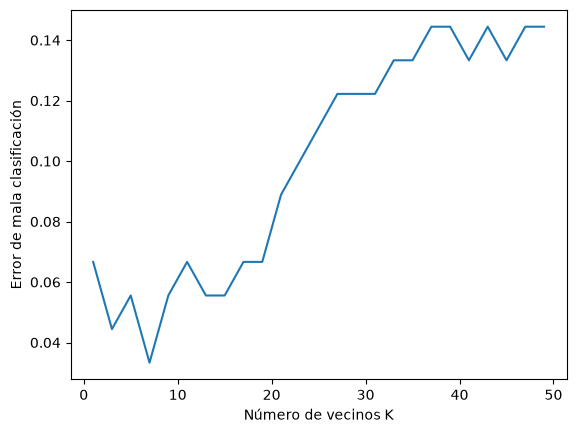

In [20]:
# cambiar a error de mala clasificación
mse = [1 - x for x in cv_scores]

# Determinar el mejor valor de k
optimal_k = neighbors[mse.index(min(mse))]
print("El número óptimo de vecinos es {}".format(optimal_k))

# grafica de error de mala clasificación vs. valor de k
plt.plot(neighbors, mse)
plt.xlabel("Número de vecinos K")
plt.ylabel("Error de mala clasificación")
plt.show()

In [15]:

classifier = KNeighborsClassifier(n_neighbors=7) # Establecemos 8 como el número de vecinos a tomar
classifier.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",7
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](3,)","['Iris-setosa','Iris-versicolor','Iris-virginica']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [16]:
y_pred = classifier.predict(X_test)

In [17]:
print("MATRIZ DE CONFUSIÓN")
print(confusion_matrix(y_test, y_pred))


MATRIZ DE CONFUSIÓN
[[20  0  0]
 [ 0 19  1]
 [ 0  2 18]]


In [18]:
print("Accuracy:")
print(accuracy_score(y_test, y_pred))

Accuracy:
0.95


In [19]:
print("Informe de métricas")
print(classification_report(y_test, y_pred))

Informe de métricas
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        20
Iris-versicolor       0.90      0.95      0.93        20
 Iris-virginica       0.95      0.90      0.92        20

       accuracy                           0.95        60
      macro avg       0.95      0.95      0.95        60
   weighted avg       0.95      0.95      0.95        60



Para evaluar el rendimiento de un *modelo KNN*, utilizamos las siguientes métricas:
- **Accuracy**: mide la corrección general de las predicciones.
- **Precision**: la proporción de predicciones positivas verdaderas respecto al total de predicciones positivas.
- **Recall** (sensibilidad): la proporción de casos positivos reales identificados correctamente.
- **F1-Score**: la media armónica (inverso de la media aritmética) de la *precision* y la *recall*, penalizando los valores bajos.(F1-score alto si `precision`y `recall`altos)
